# Test: `RegressionPicker` on California Housing

**Dataset:** California Housing (1990 census, one row per block group), as used in Aurélien Géron's *Hands-On Machine Learning*.
About 20,000 rows. The target is `median_house_value`.

It's a good test because it has:
- a **text column** (`ocean_proximity`), which checks the automatic one-hot encoding
- **missing values** in `total_bedrooms`, which shows the "clean df first" rule
- **non-linear patterns** (location, income), so tree and boosting models should beat linear ones

The notebook ends with automatic checks that print **All checks passed** if the module behaves as expected.

In [1]:
# --- Find the ML root folder and import the pickers package ---
import sys
from pathlib import Path

ml_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pickers").is_dir())
if str(ml_root) not in sys.path:
    sys.path.insert(0, str(ml_root))

%load_ext autoreload
%autoreload 2

from pickers import RegressionPicker
print("Using pickers from:", ml_root / "pickers")

Using pickers from: C:\data\GitHub\Python\pickers


## 1. Load the data

In [2]:
import pandas as pd

URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
raw = pd.read_csv(URL)
print(raw.shape)
raw.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Clean it
The picker expects a **clean** DataFrame and will refuse one with missing values. Here we just drop the ~200 incomplete rows.

Note: house values were capped at \$500,001 in the census data, so the very top end is harder to predict for every model.

In [3]:
print("Missing values before:\n", raw.isna().sum()[raw.isna().sum() > 0])

df = raw.dropna().reset_index(drop=True)
print("\nRows after cleaning:", len(df))
df["ocean_proximity"].value_counts()

Missing values before:
 total_bedrooms    207
dtype: int64

Rows after cleaning: 20433


ocean_proximity
<1H OCEAN     9034
INLAND        6496
NEAR OCEAN    2628
NEAR BAY      2270
ISLAND           5
Name: count, dtype: int64

## 3. Optional: use a sample for a faster run
With `SAMPLE_N = 5000` the full notebook takes a minute or two. Set it to `None` to use all ~20,000 rows.
With the full data, SVR and Quantile Regression are skipped automatically because they are too slow at that size.

In [4]:
SAMPLE_N = 5000          # None = use every row

data = df.sample(SAMPLE_N, random_state=42) if SAMPLE_N else df
print("Rows used:", len(data))

Rows used: 5000


## 4. Set up the picker and look at the starting hyperparameters

In [5]:
rp = RegressionPicker(data, target="median_house_value", sort="R2")

print(rp.summary())
rp.models()

Rows (train): 4,000   Features (encoded): 13   Target sd: 1.17e+05
Categorical columns one-hot encoded: ['ocean_proximity']


,Model,Family,Optional lib,Skip reason
ID,,,,
dummy,Dummy (mean),baseline,False,
lr,Linear Regression,linear,False,
ridge,Ridge,linear,False,
lasso,Lasso,linear,False,
en,Elastic Net,linear,False,
lar,Least Angle Regression,linear,False,
llar,Lasso Least Angle,linear,False,
omp,Orthogonal Matching Pursuit,linear,False,
br,Bayesian Ridge,linear,False,


In [6]:
# Starting values are worked out from the data, not the library defaults
for m in ["lasso", "knn", "dt", "hgb"]:
    print(f"{m:6}", rp.starting_params(m))

lasso  {'alpha': 805.9737803479085, 'max_iter': 5000}
knn    {'n_neighbors': 25, 'weights': 'distance'}
dt     {'min_samples_leaf': 40}
hgb    {'early_stopping': True, 'learning_rate': 0.05, 'max_iter': 1000, 'n_iter_no_change': 20}


## 5. Compare all models (5-fold CV on the training split)

In [7]:
%%time
leaderboard = rp.compare_models()
leaderboard

  Dummy (mean)                 R2=-0.0012  (1.4s)
  Linear Regression            R2=0.6541  (1.0s)
  Ridge                        R2=0.6541  (0.0s)
  Lasso                        R2=0.6512  (0.0s)
  Elastic Net                  R2=0.0003  (0.0s)
  Least Angle Regression       R2=0.6541  (0.0s)
  Lasso Least Angle            R2=0.6512  (0.0s)
  Orthogonal Matching Pursuit  R2=0.6359  (0.0s)
  Bayesian Ridge               R2=0.6541  (0.0s)
  ARD Regression               R2=0.6538  (0.1s)
  SGD Regressor                R2=0.6503  (0.0s)
  Huber Regressor              R2=0.6434  (0.1s)
  RANSAC                       R2=0.5623  (0.1s)
  Quantile (median)            R2=0.6385  (0.5s)
  Poisson GLM                  R2=0.6159  (0.0s)
  Gamma GLM                    R2=0.5059  (0.0s)
  Tweedie GLM                  R2=0.5803  (0.0s)
  K Neighbors                  R2=0.6800  (0.1s)
  Support Vector (RBF)         R2=0.7481  (0.4s)
  Decision Tree                R2=0.6433  (0.1s)
  Random Forest    

,Model,MAE,RMSE,R2,R2 SD,MAPE,Fit (s)
ID,,,,,,,
xgboost,XGBoost,34967.7707,51419.7065,0.8062,0.0059,0.1938,0.5472
hgb,Hist Gradient Boosting,36295.3993,53221.9728,0.7924,0.0078,0.1984,0.3064
gbr,Gradient Boosting,38184.2855,54702.9016,0.7806,0.0106,0.2127,1.3990
rf,Random Forest,39090.1987,57308.8576,0.7595,0.0108,0.2177,3.2734
et,Extra Trees,40073.2305,58345.9276,0.7508,0.0096,0.2225,1.9101
svr,Support Vector (RBF),39653.8405,58641.1453,0.7481,0.0068,0.2103,0.2765
knn,K Neighbors,46382.9983,66089.4280,0.6800,0.0171,0.2550,0.0091
br,Bayesian Ridge,50623.8294,68711.8989,0.6541,0.0121,0.2915,0.0072
ridge,Ridge,50632.4602,68713.2402,0.6541,0.0121,0.2917,0.0072


## 6. Tune the top 3
Each model is tuned with a random search. The tuned version is kept only if it beats the starting version in cross-validation.
Then both are checked on the 20% holdout set that hasn't been touched yet.

In [8]:
%%time
tuned = rp.tune_top(n=3, n_iter=20)
tuned

  XGBoost                      start=0.8062  tuned=0.8059  -> keep starting
  Hist Gradient Boosting       start=0.7924  tuned=0.7946  -> keep tuned
  Gradient Boosting            start=0.7806  tuned=0.7959  -> keep tuned
CPU times: total: 9.17 s
Wall time: 39.3 s


,Model,CV R2 (start),CV R2 (tuned),Kept,Holdout MAE,Holdout RMSE,Holdout R2,Holdout MAPE,Tune (s)
ID,,,,,,,,,
xgboost,XGBoost,0.8062,0.8059,starting,32079.8164,47128.1524,0.8309,0.1799,9.3987
gbr,Gradient Boosting,0.7806,0.7959,tuned,32753.9521,47621.4793,0.8274,0.1882,18.1838
hgb,Hist Gradient Boosting,0.7924,0.7946,tuned,32702.2801,47636.9267,0.8273,0.1858,8.9362


In [9]:
print(rp.summary())

Rows (train): 4,000   Features (encoded): 13   Target sd: 1.17e+05
Categorical columns one-hot encoded: ['ocean_proximity']

Best model: XGBoost (xgboost)
Holdout R2: 0.8309
Recommended hyperparameters:
  colsample_bytree = 0.8
  learning_rate = 0.05
  max_depth = 6
  n_estimators = 500
  subsample = 0.8
  tree_method = hist


In [10]:
# Recommended hyperparameters for every tuned model
for model_id, params in rp.recommended_params_.items():
    print(model_id, params)

xgboost {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 500, 'subsample': 0.8, 'tree_method': 'hist'}
hgb {'early_stopping': True, 'learning_rate': 0.078825, 'max_iter': 1000, 'n_iter_no_change': 20, 'l2_regularization': 6.703113, 'max_features': 0.638, 'max_leaf_nodes': 36, 'min_samples_leaf': 19}
gbr {'learning_rate': 0.035747, 'n_estimators': 1000, 'n_iter_no_change': 20, 'subsample': 0.889846, 'max_depth': 6, 'max_features': 0.5, 'min_samples_leaf': 11}


## 7. Predicted vs actual on the holdout set

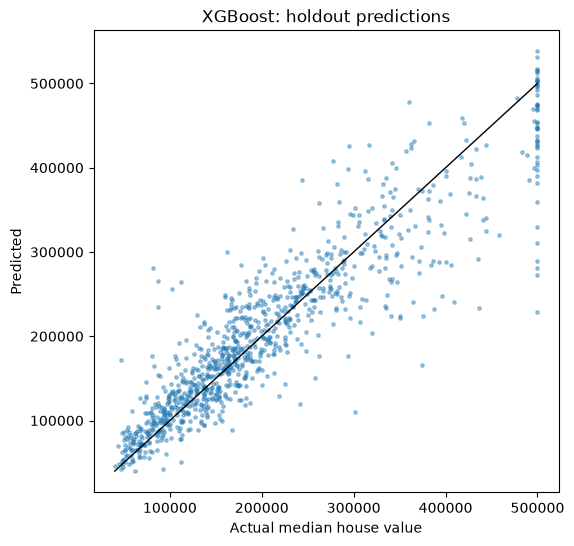

In [11]:
import matplotlib.pyplot as plt

best_id = rp.tuned_.index[0]
pred = rp.get_model(best_id).predict(rp.X_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(rp.y_test, pred, s=6, alpha=0.4)
lims = [rp.y_test.min(), rp.y_test.max()]
ax.plot(lims, lims, color="black", linewidth=1)
ax.set_xlabel("Actual median house value")
ax.set_ylabel("Predicted")
ax.set_title(f"{rp.specs[best_id].name}: holdout predictions")
plt.show()

## 8. Use the final model
`finalize()` refits the winner on **all** rows (train + holdout), ready for new data.

In [12]:
final_model = rp.finalize()

new_rows = data.drop(columns="median_house_value").head(5)
pd.DataFrame({"actual": data["median_house_value"].head(5).values,
              "predicted": final_model.predict(new_rows).round(0)})

,actual,predicted
0,245800.0,231838.0
1,137900.0,139922.0
2,218200.0,202823.0
3,220800.0,184193.0
4,170500.0,170778.0


## 9. Automatic checks

In [13]:
import numpy as np

lb, tu = rp.leaderboard_, rp.tuned_
best = tu.index[0]

checks = {
    "leaderboard has 15+ models":                   len(lb) >= 15,
    "dummy baseline is in the leaderboard":         "dummy" in lb.index,
    "best CV R2 beats dummy by 0.3+":               lb["R2"].max() > lb.loc["dummy", "R2"] + 0.3,
    "text column was one-hot encoded":              rp.cat_cols == ["ocean_proximity"],
    "3 models were tuned":                          len(tu) == 3,
    "tuned models have recommended params":         all(m in rp.recommended_params_ for m in tu.index),
    "best holdout R2 is above 0.70":                tu.loc[best, "Holdout R2"] > 0.70,
    "a tree/boosting model won (data is non-linear)": rp.specs[best].family == "ensemble",
    "final model predicts one value per row":       len(final_model.predict(new_rows)) == len(new_rows),
    "missing values are rejected":                  False,
}

try:
    RegressionPicker(raw, target="median_house_value")
except ValueError:
    checks["missing values are rejected"] = True

for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)

assert all(checks.values()), "Some checks failed - see above"
print("\nAll checks passed")

PASS  leaderboard has 15+ models
PASS  dummy baseline is in the leaderboard
PASS  best CV R2 beats dummy by 0.3+
PASS  text column was one-hot encoded
PASS  3 models were tuned
PASS  tuned models have recommended params
PASS  best holdout R2 is above 0.70
PASS  a tree/boosting model won (data is non-linear)
PASS  final model predicts one value per row
PASS  missing values are rejected

All checks passed
